# **Первичный анализ данных**

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
%matplotlib inline

In [14]:
url_red = 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv'
df = pd.read_csv(url_red, sep=';')

print(f'{df.shape} - до удаления дупликатов')
print(f'{round(float(df.duplicated().sum() / df.shape[0]), 2) * 100} % дупликатов')
df = df.drop_duplicates().reset_index(drop=True)
print(f'{df.shape} - после удаления дупликатов')

df.head()

(1599, 12) - до удаления дупликатов
15.0 % дупликатов
(1359, 12) - после удаления дупликатов


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5


Изначально датасет красного вина содержит 1599 объектов, однако обнаружено 15% полных дубликатов (240 строк), после удаления которых осталось 1359 уникальных образцов. Удаление дубликатов до разбиения необходимо, чтобы одинаковые объекты не попали одновременно в обучающую и тестовую выборки

In [15]:
df.isna().sum()

,0
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


Пропуски отсутствуют во всех столбцах

In [16]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['quality'])
y = df['quality']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
train = X_train.assign(quality=y_train)

Выборка разделена в пропорции 80% на обучение (1087 объектов) и 20% на тест (272 объекта) с фиксацией `random_state=42` для воспроизводимости. Такое соотношение оставляет достаточно данных для обучения и даёт репрезентативный тест. Разбиение выполнено со стратификацией по целевой переменной (`stratify=y`), чтобы сохранить одинаковые пропорции редких оценок (3, 4, 8) в обеих выборках.

Если многократно проверять модели по одной и той же тестовой выборке, возникает переобучение под тест, из-за чего финальная оценка качества оказывается оптимистично завышенной.

In [17]:
stats = train.describe().T[['mean', 'std', 'min', '50%', 'max']]
stats['skew'] = train.skew()
stats['kurtosis'] = train.kurtosis()
stats

,mean,std,min,50%,max,skew,kurtosis
fixed acidity,8.329715,1.789372,4.60000,7.9000,15.9000,0.904414,0.853567
volatile acidity,0.532010,0.185692,0.16000,0.5200,1.5800,0.768560,1.404573
citric acid,0.272898,0.196584,0.00000,0.2600,1.0000,0.337642,-0.772684
residual sugar,2.533211,1.346875,0.90000,2.2000,15.5000,4.488060,28.499216
chlorides,0.087305,0.047645,0.01200,0.0790,0.6110,5.872794,45.181719
free sulfur dioxide,16.004140,10.615658,1.00000,14.0000,72.0000,1.233823,1.927415
total sulfur dioxide,47.329807,34.332869,6.00000,38.0000,289.0000,1.590023,4.343481
density,0.996704,0.001920,0.99007,0.9967,1.0032,-0.020180,0.676457
pH,3.308583,0.158854,2.74000,3.3100,4.0100,0.279705,0.952241
sulphates,0.655989,0.169598,0.37000,0.6200,2.0000,2.499240,12.360783


In [18]:
y_train.value_counts(sort=False)

,count
quality,
6,428
7,134
5,461
4,42
8,14
3,8


<Axes: xlabel='quality', ylabel='Count'>

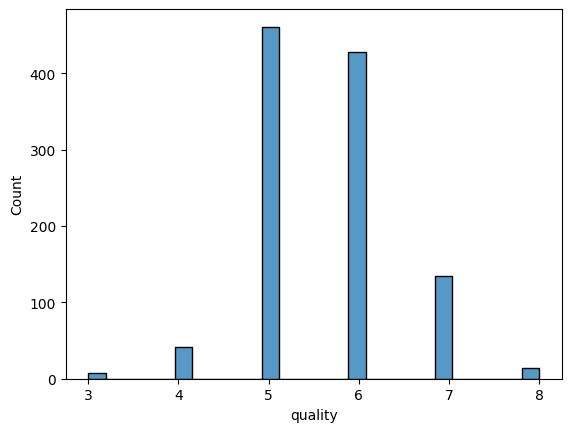

In [19]:
sns.histplot(y_train)

Целевая переменная `quality` принимает дискретные значения от 3 до 8 и имеет сильный дисбаланс: более 94% обучающей выборки приходится на оценки 5 (461), 6 (428) и 7 (134), тогда как крайние классы представлены единичными примерами (3 -8 шт., 8 - 14 шт., 4 - 42 шт.). Из-за этого моделям будет трудно предсказывать высокое или низкое качество.

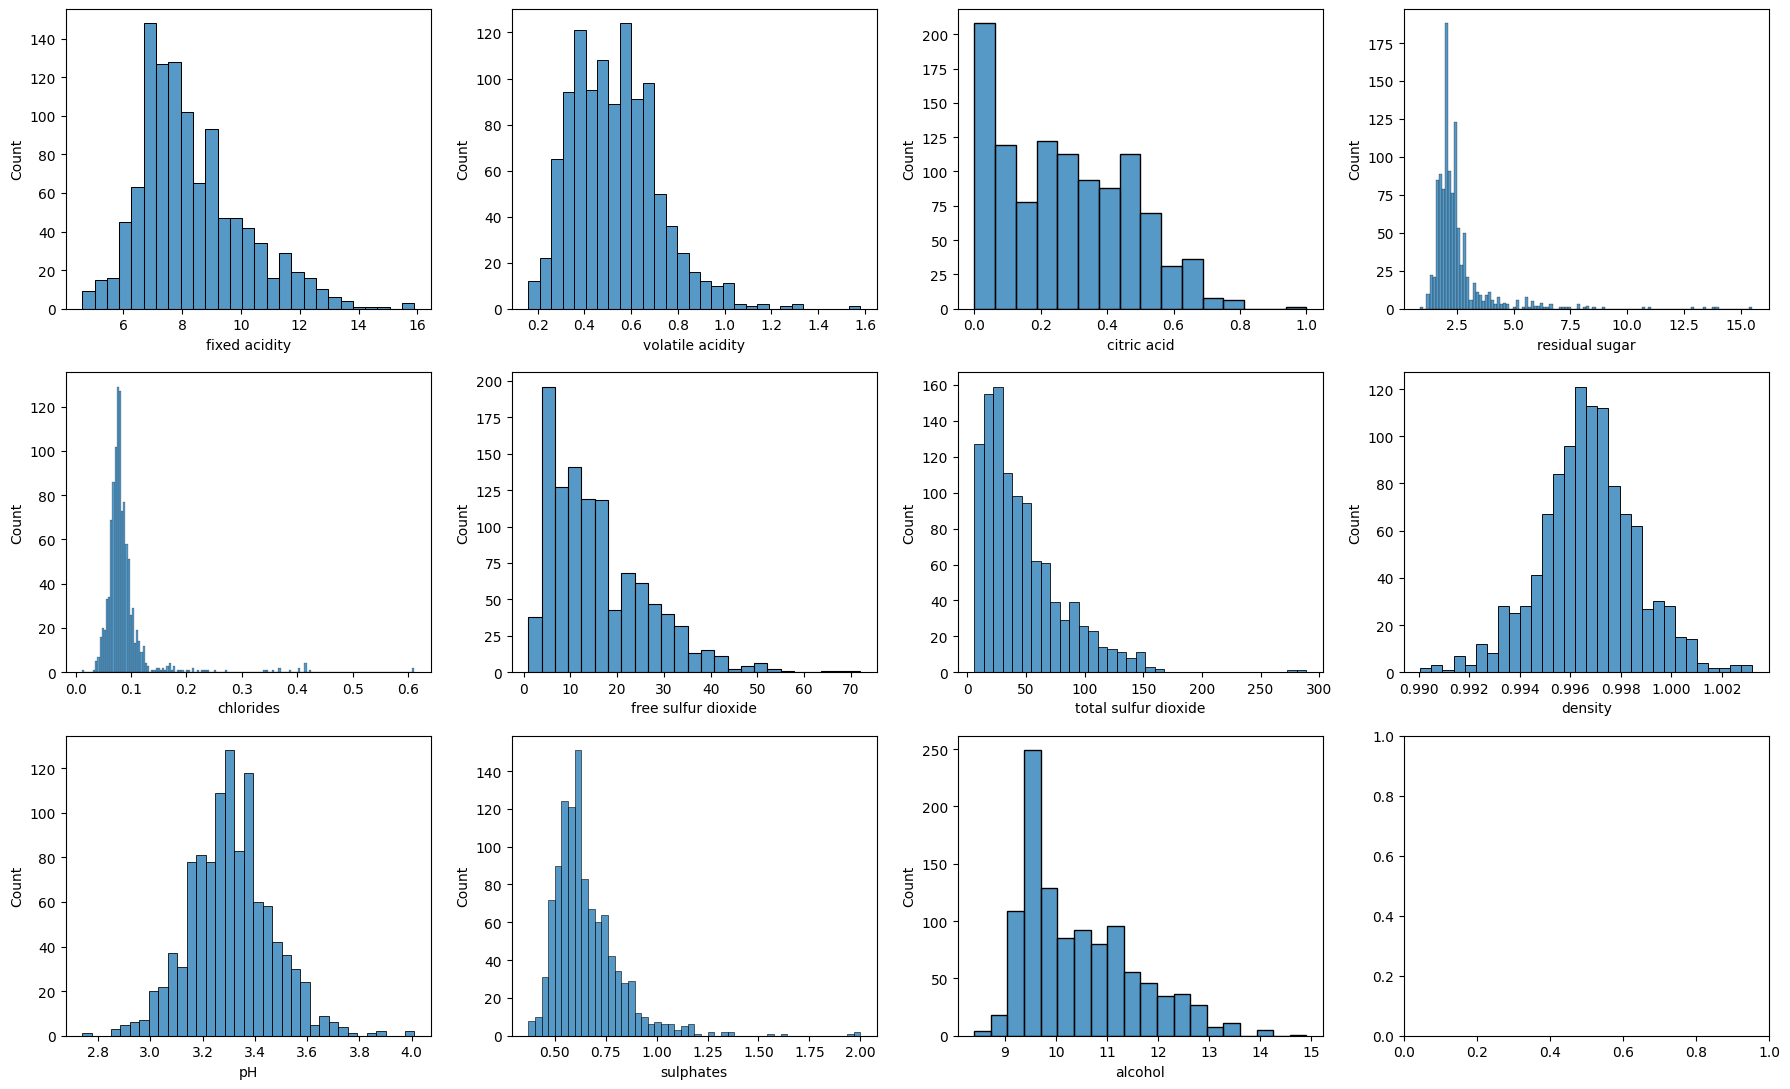

In [20]:
feat_cols = X.columns

fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, c in zip(axes.ravel(), feat_cols):
    sns.histplot(train[c], ax=ax)

plt.tight_layout()
plt.show()

Признаки измерены в разных единицах и порядках величин (например, `density` около 0.997, а `total sulfur dioxide` доходит до 289), что требует масштабирования перед обучением линейных моделей. Большинство признаков имеют правостороннюю асимметрию и выбросы (особенно `chlorides` (5.87), а также `residual` `sugar` (4.49) и `free sulfur dioxide`)

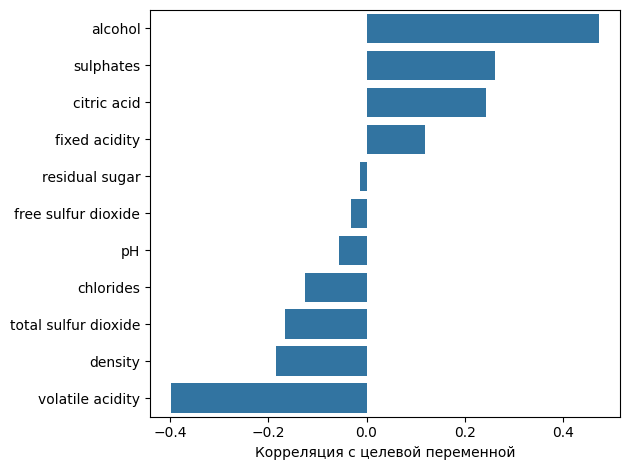

In [21]:
correlations = X_train.corrwith(y_train).sort_values(ascending=False)

plot = sns.barplot(y=correlations.index, x=correlations)

plot.set(xlabel="Корреляция с целевой переменной", ylabel="")

plt.tight_layout()
plt.show()

Наиболее сильная положительная корреляция с целевой переменной наблюдается у `alcohol` (0.47) - более крепкие вина в среднем получают более высокие оценки дегустаторов, поэтому этот признак станет главным предиктором. Умеренная положительная связь также присутствует у `sulphates` (0.26) и `citric acid` (0.24), слабая - у `fixed acidity` (0.12). Наиболее заметная отрицательная корреляция наблюдается у `volatile acidity` (-0.40, избыток летучих кислот даёт резкий уксусный привкус и снижает оценку), а более слабая отрицательная - у `density` (-0.18), `total sulfur dioxide` (-0.17) и `chlorides` (-0.12).

<Axes: >

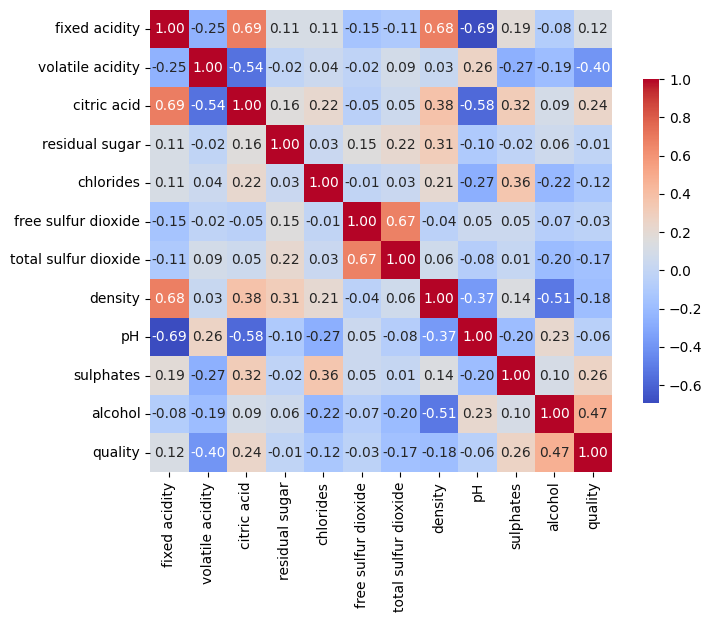

In [22]:
corr_matrix = train.corr()
plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', square=True, cbar_kws={'shrink': 0.7})

Выявлена сильная взаимная корреляция (мультиколлинеарность) между рядом физико-химических признаков красного вина: `fixed acidity` тесно связан с `pH` (-0.69, чем больше нелетучих кислот, тем выше кислотность и ниже показатель `pH`), `citric acid` (0.69, лимонная кислота входит в состав общей фиксированной кислотности) и `density` (0.68, кислоты повышают плотность сусла). `free sulfur dioxide` и `total sulfur dioxide` (0.67, свободный диоксид серы является частью общего).   `citric acid` заметно коррелирует с `pH` (-0.58) и `volatile acidity` (-0.54). `density` отрицательно связан с `alcohol` (-0.51, спирт менее плотный, чем вода) и умеренно положительно - с `citric acid` (0.38) и `residual sugar` (0.31).   Наличие этих связей необходимо учитывать при интерпретации коэффициентов линейной регрессии.

# **Подготовка выборок и обучение моделей**

In [23]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.fit(X_train)

X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

Признаки отмасштабированы через `StandardScaler` (обучен только на `X_train`). Для обычной линейной регрессии без регуляризации масштабирование не меняет качество прогноза, но необходимо для интерпретации коэффициентов: без него веса признаков в разных единицах измерения (`density` против `total sulfur dioxide`) нельзя сравнивать между собой

In [24]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

models = {
    'Baseline': DummyRegressor(strategy='mean'),
    'LinearRegression': LinearRegression(),
    'RandomForestRegressor': RandomForestRegressor(random_state=42),
    'GradientBoostingRegressor': GradientBoostingRegressor(random_state=42)
}

В качестве базового решения использован `DummyRegressor(strategy='mean')`, предсказывающий константу - среднее значение `quality` по обучающей выборке.

In [25]:
rows = []
coefs = []

for name, model in models.items():
  model.fit(X_train_scaled, y_train)
  pred = model.predict(X_test_scaled)
  if hasattr(model, 'coef_'):
    coefs.append({'model': name, 'coef': model.coef_})
  elif hasattr(model, 'feature_importances_'):
    coefs.append({'model': name, 'coef': model.feature_importances_})
  rows.append({
      'model': name,
      'RMSE': root_mean_squared_error(y_test, pred),
      'MAE': mean_absolute_error(y_test, pred),
  })

`MAE` показывает среднюю абсолютную ошибку ($\frac{1}{n}\sum \vert{}y_i - \hat{y}_i\vert{}$) - на сколько баллов качества в среднем ошибается модель.

`RMSE` - это корень из среднеквадратичной ошибки ($\sqrt{\frac{1}{n}\sum (y_i - \hat{y}_i)^2}$) - среднеквадратичное отклонение предсказаний от истинных ответов в исходных единицах измерения

`RMSE` сильнее реагирует на большие ошибки из-за возведения ошибок в квадрат перед усреднением крупные промахи получают квадратично больший вес, тогда как в `MAE` все ошибки учитываются линейно

Чем больше дисперсия ошибок и чем чаще встречаются грубые выбросы на отдельных объектах (в нашей задаче - на редких классах 3, 4, 8), тем сильнее `RMSE` превышает `MAE`

In [26]:
results = pd.DataFrame(rows).sort_values("RMSE")
results

,model,RMSE,MAE
2,RandomForestRegressor,0.622633,0.477096
3,GradientBoostingRegressor,0.634063,0.496451
1,LinearRegression,0.652303,0.506552
0,Baseline,0.819127,0.692066


Все обученные модели значительно превзошли `Baseline` (`RMSE` = 0.819) и успешно прошли целевой порог `RMSE` < 0.70.   `LinearRegression` преодолела порог (`RMSE` = 0.652), однако уступила деревянным ансамблям, поскольку способна восстанавливать только линейные зависимости и чувствительна к мультиколлинеарности и выбросам в признаках.

Качество вина нелинейно зависит от сочетания физико-химических свойств (например, баланса летучих кислот, сульфатов и спирта), и деревья решений эффективно улавливают такие взаимодействия. Лучший результат на тестовой выборке показал `RandomForestRegressor` с параметрами по умолчанию (`RMSE` = 0.623), немного опередив `GradientBoostingRegressor` (`RMSE` = 0.634).

# **Feature importance**

In [27]:
def show_weights(features, weights, title, ax=None):
    if ax is None:
      fig, ax = plt.subplots(figsize=(8, 6))

    sorted_weights = sorted(zip(weights, features), reverse=True)
    weights = [x[0] for x in sorted_weights]
    features = [x[1] for x in sorted_weights]

    sns.barplot(y=features, x=weights, ax=ax)
    ax.set_xlabel("Weight")


    ax.set_title(title, fontsize=14, fontweight='bold', pad=12)
    ax.set_xlabel("Вес признака", fontsize=11)
    ax.set_ylabel("")
    ax.axvline(0, color='gray', linestyle='--', linewidth=0.8, alpha=0.7)
    ax.grid(axis='x', linestyle=':', alpha=0.6)
    sns.despine(ax=ax, left=False, bottom=False)

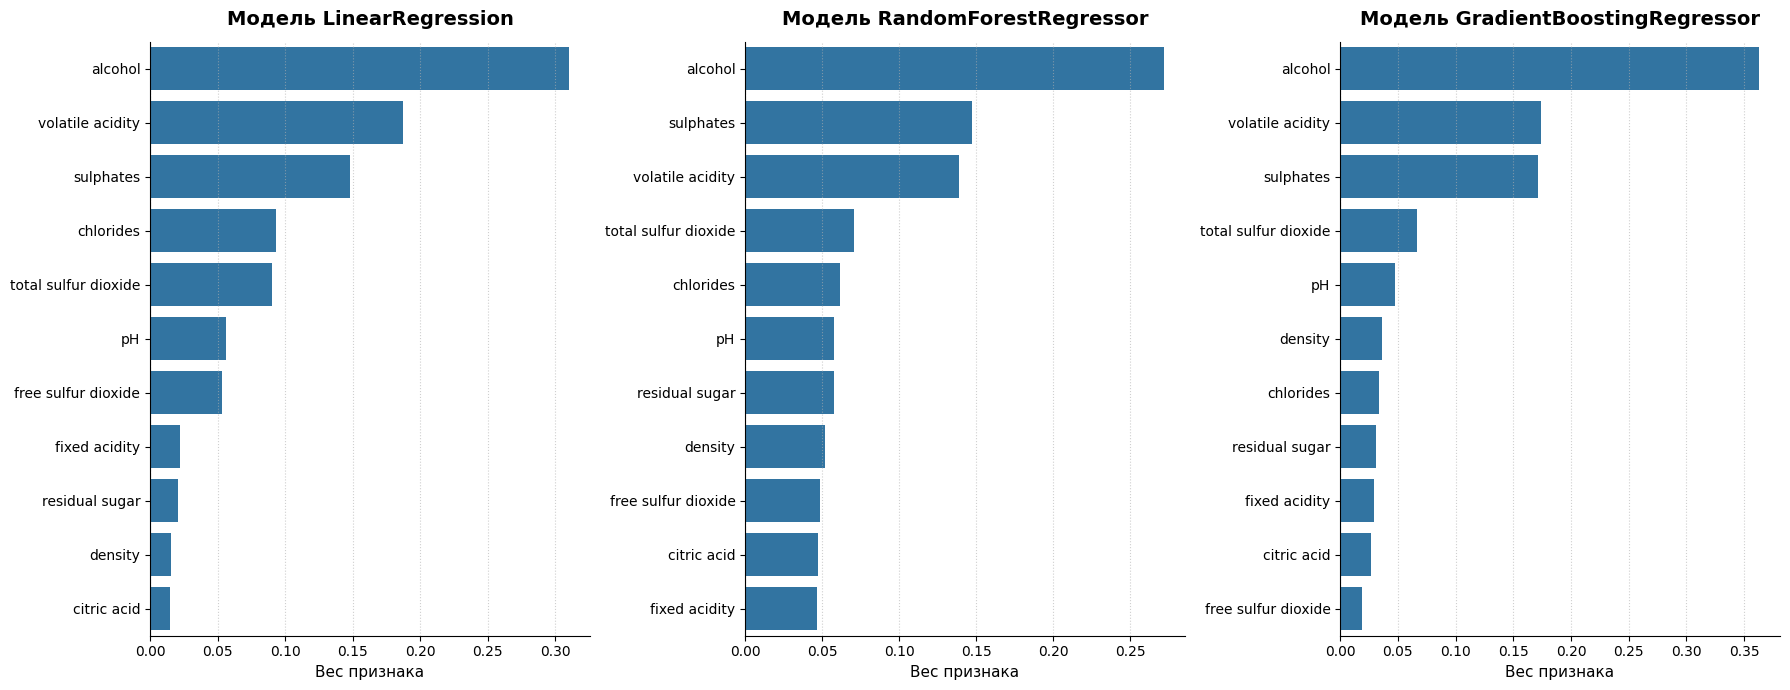

In [28]:
n_models = len(coefs)
fig, axes = plt.subplots(ncols=n_models, figsize=(6 * n_models, 7))


for ax, model_info in zip(axes, coefs):
  name = model_info['model']
  coef = abs(model_info['coef'])
  show_weights(X.columns, coef, f'Модель {name}', ax=ax)

plt.tight_layout()
plt.show()




`LinearRegression`: Наибольшие по модулю стандартизованные коэффициенты получили `alcohol` (0.31), `volatile acidity` (0.19), `sulphates` (0.15), `chlorides` (0.09) и `total sulfur dioxide` (0.09). При этом `citric acid`, несмотря на заметную парную корреляцию с целевой переменной (0.24), получил самый маленький вес в линейной модели, так как его информация дублируется сильно скоррелированными с ним признаками кислотности (`fixed acidity`, `volatile acidity`, `pH`).

`RandomForestRegressor` и `GradientBoostingRegressor`: Оба ансамбля деревьев выделили ту же тройку ключевых факторов - `alcohol` (безусловный лидер с большим отрывом), `sulphates` и `volatile acidity` (делят 2-е и 3-е места), за которыми на 4-м месте следует `total sulfur dioxide`, а далее - `chlorides` и `pH`. Это полностью подтверждает выводы первичного анализа данных (EDA). Остальные признаки (`residual sugar, density`, `free sulfur dioxide`, `citric acid`, `fixed acidity`) имеют меньшую и примерно равную значимость, помогая деревьям уточнять предсказания в отдельных разбиениях.

# **Анализ ошибок**

<Axes: ylabel='Count'>

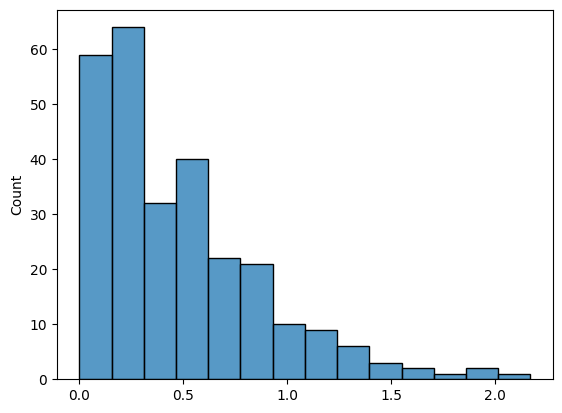

In [29]:
model = RandomForestRegressor(random_state=42)
model.fit(X_train_scaled, y_train)
y_pred = pd.Series(model.predict(X_test_scaled), index=y_test.index)z
error = (y_test - y_pred).abs()
sns.histplot(error)


In [30]:
df_results = pd.DataFrame({
    'y_true':y_test,
    'y_pred':y_pred.round(2),
    'error': error.round(2),
})

Распределение абсолютных ошибок лучшей модели (`RandomForestRegressor`) сконцентрировано вблизи нуля (большинство ошибок < 0.6), но имеет правый хвост до 2.17 балла

In [31]:
df_results.groupby('y_true')['error'].agg(['count', 'mean', 'median'])

,count,mean,median
y_true,,,
3,2,2.080000,2.080
4,11,1.059091,1.030
5,116,0.371293,0.285
6,107,0.404860,0.350
7,33,0.715455,0.560
8,3,1.320000,1.240


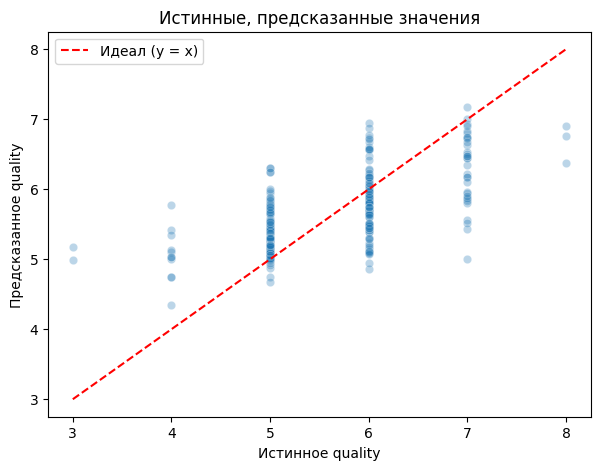

In [32]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.3)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', label='Идеал (y = x)')
plt.xlabel('Истинное quality')
plt.ylabel('Предсказанное quality')
plt.title('Истинные, предсказанные значения')
plt.legend()
plt.show()

На массовых классах 5 и 6 средняя абсолютная ошибка минимальна , на классе 7 - умеренная. Модель работает неравномерно для разных оценок `quality`. На редких классах ошибка резко растёт.

In [33]:
df_max = df_results.nlargest(20, 'error').reset_index()
df_max

,index,y_true,y_pred,error
0,718,3,5.17,2.17
1,1165,3,4.99,1.99
2,6,7,5.01,1.99
3,608,4,5.77,1.77
4,434,8,6.38,1.62
5,1243,7,5.43,1.57
6,558,7,5.52,1.48
7,978,7,5.56,1.44
8,1050,4,5.42,1.42
9,1074,4,5.34,1.34


In [34]:
max_idx = error.nlargest(n=5)
X_test.loc[max_idx.index]

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
718,10.4,0.440,0.42,1.5,0.145,34.0,48.0,0.99832,3.38,0.86,9.9
1165,6.8,0.815,0.00,1.2,0.267,16.0,29.0,0.99471,3.32,0.51,9.8
6,7.3,0.650,0.00,1.2,0.065,15.0,21.0,0.99460,3.39,0.47,10.0
608,7.5,0.380,0.48,2.6,0.073,22.0,84.0,0.99720,3.32,0.70,9.6
434,10.7,0.350,0.53,2.6,0.070,5.0,16.0,0.99720,3.15,0.65,11.0


Индексы 718 и 1165 (`y_true` = 3, прогноз 5.17 и 4.99, ошибка 2.17 и 1.99): у образца 718 низкая летучая кислотность (`volatile acidity` = 0.44), высокое содержание сульфатов (0.86) и лимонной кислоты (0.42) при среднем алкоголе (9.9%), поэтому по физико-химическим свойствам он выглядит как типичное вино класса 5. У образца 1165 выражены негативные факторы (высокая летучая кислотность 0.815 и хлориды 0.267), но из-за того, что в обучающей выборке было всего 8 примеров класса 3, модель не рискует предсказывать оценки ниже 5.

Индекс 6 (`y_true` = 7, прогноз 5.01, ошибка 1.99): образец имеет невысокую крепость (`alcohol` = 10.0%), повышенную летучую кислотность (0.65), нулевую лимонную кислоту (0.00) и низкие сульфаты (0.47). По всем основным предикторам это рядовое вино категории 5, однако дегустаторы поставили ему высокую оценку 7.

Индекс 608 (`y_true` = 4, прогноз 5.77, ошибка 1.77): низкая летучая кислотность (0.38), высокая лимонная кислота (0.48) и хорошие сульфаты (0.70) заставили модель дать завышенный прогноз, несмотря на низкую оценку экспертов.

Индекс 434 (`y_true` = 8, прогноз 6.38, ошибка 1.62): хорошее вино с повышенным содержанием спирта (11.0%) и низкой летучей кислотностью (0.35), но из-за крайней редкости класса 8 в обучающей выборке (14 шт.) и малого количества диоксида серы (`free/total sulfur dioxide` = 5.0 и 16.0) предсказание модели сгладилось к диапазону 6–7. Кроме того, субъективная оценка дегустаторов зависит от прочих свойств, не отражённых в 11 базовых признаках.

In [35]:
df_min = df_results.nsmallest(20, 'error').reset_index()
df_min

,index,y_true,y_pred,error
0,157,5,5.00,0.00
1,1167,5,5.00,0.00
2,131,5,5.00,0.00
3,1252,7,7.00,0.00
4,1174,5,4.99,0.01
5,480,6,6.01,0.01
6,363,5,5.01,0.01
7,614,6,6.02,0.02
8,1233,6,5.98,0.02
9,1115,5,5.02,0.02


Модель хуже предсказывает редкие значения `quality`, потому что в обучающей выборке критически мало объектов с оценками 3 (8 шт.), 8 (14 шт.) и 4 (42 шт.), из-за чего деревьям недостаточно данных для уверенного выделения этих областей признакового пространства. Случайный лес усредняет ответы ста деревьев и оптимизирует среднеквадратичную ошибку, что математически стягивает предсказания к условному математическому ожиданию (ближе к самым массовым оценкам 5 и 6), сглаживая экстремальные прогнозы.